<a href="https://colab.research.google.com/github/RaisHult/Team-E-A2-Group-Project-Resources-/blob/main/Airline_Profitability_Route_Profitability_%26_Cost_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **The Main Business Problem**

Airlines operate in a highly cost-intensive industry where profitability depends on the interaction between operational efficiency, revenue generation and route characteristics.

The objective of this analysis is to identify the key structural drivers of airline route profitability by examining operational variables, cost structures and demand factors. Exploratory Data Analysis (EDA), feature selection, interaction analysis and Pricipal Component Analysis (PCA) are used to uncover underlying financial patterns across routes.

**Stakeholder Questions**


1.   What operational cost factors most strongly influence airline route profitability?
2.   Do route categories (short, medium, long) exhibit distinct financial structures?


1.   How do aircraft types affect cost efficiency across routes?
2.   Does seasonality significantly impact profit margins?









# **Initial Data Exploration**

To begin the exploratory data analysis, I first loaded the dataset into a pandas DataFrame using pd.read_csv(). This step was key to allowing the dataset to be stored in a structured format that can be easily manipulated and analysed using Python.

I used 3 initial commands to understand the structure and content of the dataset:


*   df.head() was used to preview the first few rows of the dataset and verify that the data was imported correctly
*   df.info() was used to examine the dataset structure, including the number of rows, column names, data types and the presence of any missing values


*   df.describe() was used to display a summary of statstics for all numerical variables, including the mean, standard deviation, minimum and maximum values and quartiles

The output shows that the dataset contains 7,974 observations across 33 variables, consisting of a mix of numerical variables (such as revenue, costs and passenger counts) and categorical variables (such as aircraft type, route category and season).


In [1]:
import pandas as pd
df = pd.read_csv("airline_route_profitability.csv")
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7974 entries, 0 to 7973
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Flight_Number            7974 non-null   object 
 1   Flight_Date              7974 non-null   object 
 2   Origin                   7974 non-null   object 
 3   Destination              7974 non-null   object 
 4   Route                    7974 non-null   object 
 5   Aircraft_Type            7974 non-null   object 
 6   Aircraft_Capacity        7974 non-null   int64  
 7   Passengers               7974 non-null   int64  
 8   Load_Factor              7974 non-null   float64
 9   Flight_Hours             7974 non-null   float64
 10  Season                   7974 non-null   object 
 11  Route_Category           7974 non-null   object 
 12  Demand_Level             7974 non-null   object 
 13  Ticket_Revenue           7974 non-null   float64
 14  Ancillary_Revenue       

,Aircraft_Capacity,Passengers,Load_Factor,Flight_Hours,Ticket_Revenue,Ancillary_Revenue,Total_Revenue,Fuel_Cost,Maintenance_Cost,Crew_Cost,...,Handling_Cost,Navigation_Fees,Sales_Distribution_Cost,Passenger_Service_Cost,Overhead_Cost,Marketing_Cost,IT_Systems_Cost,Total_Cost,Profit,Profit_Margin
count,7974.000000,7974.000000,7974.000000,7974.000000,7.974000e+03,7703.000000,7.974000e+03,7974.000000,7974.000000,7974.000000,...,7718.000000,7974.000000,7974.000000,7974.000000,7974.000000,7974.000000,7974.000000,7974.000000,7974.000000,7974.000000
mean,317.800602,254.819162,0.801570,6.327314,2.643839e+05,33073.717197,2.974362e+05,46296.405878,18973.224856,8905.116880,...,3988.998616,3785.569431,44659.242364,5721.982070,35742.265706,13448.184059,2930.738501,225266.563756,72169.633934,6.190222
std,98.768543,88.141968,0.087755,4.555668,2.371022e+05,30167.518230,2.668329e+05,43123.036900,17677.194300,7414.772748,...,1146.741218,2861.881472,40575.117395,2295.208112,29368.802114,12633.987523,1154.464363,174526.327680,138692.750890,39.040588
min,180.000000,104.000000,0.576600,1.200000,1.481234e+04,1616.620000,1.665002e+04,2592.620000,1380.000000,936.000000,...,2000.040000,483.570000,2143.110000,1750.110000,3750.190000,608.620000,923.260000,28019.380000,-250914.850000,-236.270000
25%,296.000000,180.250000,0.736825,3.200000,5.642951e+04,7234.405000,6.350239e+04,16137.575000,7040.000000,3840.000000,...,2991.377500,1602.465000,9690.980000,4002.195000,13955.147500,2942.397500,2063.495000,83612.367500,-9052.485000,-10.747500
50%,325.000000,246.000000,0.801500,4.500000,1.826204e+05,22842.850000,2.048126e+05,28344.950000,11200.000000,5850.000000,...,3971.835000,2879.290000,31167.845000,5386.070000,24366.945000,9235.870000,2772.270000,154808.355000,21326.055000,15.215000
75%,396.000000,302.000000,0.873100,7.500000,4.126969e+05,51234.975000,4.638002e+05,74832.960000,30800.000000,13000.000000,...,4974.315000,5084.895000,68973.712500,7018.972500,54205.342500,20226.527500,3576.795000,355441.002500,116046.090000,33.280000
max,517.000000,491.000000,0.950000,16.500000,1.303645e+06,192921.910000,1.496567e+06,191047.780000,72500.000000,29000.000000,...,5999.980000,13166.360000,222595.180000,14601.280000,144736.040000,78018.070000,7354.160000,835108.700000,972133.760000,64.960000


# **Data Cleaning**

Before conducting a deeper exploratory analysis, I looked for potential data quality issues such as missing values, duplicate records and inconsistencies. Data cleaning is an essential step in EDA because errors or incomplete records can distort statistical results and affect modelling techniques such as feature selection and PCA.

**Missing Values**

The dataset was checked for missing values using the command:

```
   df.insnull().sum()
```

This allowed each variable to be checked to find out whether any observations contained missing values. Identifying missing values is important because incomplete data can potential influence the stastical summaries and modelling. If missing values are detected, appropriate strategies such as imputation or removal can be applied depending on the proportion and importance of the affected variable.

**Duplicate Records**

The dataset was also checked for duplicate observations using:



```
  df.duplicated().sum()
```

Duplicate records can occur during data collection or aggregation process which can cause analytical bias in the results if they are not removed. This is to make sure that each observation represents a unique flight.

**Dataset Dimensions**

To confirm the size of the dataset and verify that no unintended changes occured during data loading, the dataset dimensions were inspected using:


```
  df.shape
```

The dataset contains 7,974 observations, with each row representing a single fight and each column representing operational or financial attributes associated with that flight.  


In [2]:
df.isnull().sum()

,0
Flight_Number,0
Flight_Date,0
Origin,0
Destination,0
Route,0
Aircraft_Type,0
Aircraft_Capacity,0
Passengers,0
Load_Factor,0
Flight_Hours,0


# **Missing Value Analysis**

The results indicate that most variables contain complete observations, suggesting that the dataset is largely well-populated. however, a small number of missing values were identified in 3 variables:


1.   Ancillary_Revenue = 271 missing values
2.   Catering_Cost = 265 missing values

1.   Handling_Cost = 256 missing values


Given that the dataset contains 7,974 total observations, the proportion of missing values in these variables is relatively small. All other operational and financial variables often exhibit skewed disributions, and the median is less influenced by extreme values.



In [3]:
df["Ancillary_Revenue"].fillna(df["Ancillary_Revenue"].median(), inplace=True)
df["Catering_Cost"].fillna(df["Catering_Cost"].median(), inplace=True)
df["Handling_Cost"].fillna(df["Handling_Cost"].median(), inplace=True)
df.isnull().sum()

/tmp/ipykernel_184/2240736554.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Ancillary_Revenue"].fillna(df["Ancillary_Revenue"].median(), inplace=True)
/tmp/ipykernel_184/2240736554.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method

,0
Flight_Number,0
Flight_Date,0
Origin,0
Destination,0
Route,0
Aircraft_Type,0
Aircraft_Capacity,0
Passengers,0
Load_Factor,0
Flight_Hours,0


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.shape

(7974, 33)

# **Final Data Quality Check**

After imputing missing values and checking for duplicate records, I re-evaluated the dataset to confirm that all variables contained complete observations. This shows that no missing values remain across any of the variables, indicating that the dataset is now fully populated and suitable for further exploratory analysis.

Additionally, a duplicate check confirmed that no duplicate records were present, meaning each row represents a unique flight observation.

So the final dataset contains 7,974 observations and 33 variables, providing a sufficiently large and complete dataset for a sufficent EDA and dimensionality reduction using PCA.

# **Exploratory Data Analysis**

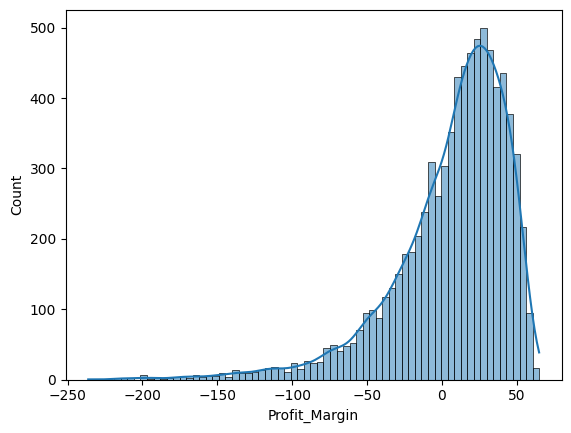

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df["Profit_Margin"], kde=True)
plt.show()

**Profit Margin Distribution**

The distribution of the profit margins shows that most flights operate with moderately positive profitability, with the highest concentration between 0% and 40% proft margin. However, the distribution is left-skewed with a long tail extending into negative values.

This highlights that even though many routes generate profit, a proportion of flights experience significant losses in some cases exceeding -200% profit margin. This suggests that certain operational or route characteristics may lead to highly unprofitable flights, which is grounds for further investigation.  

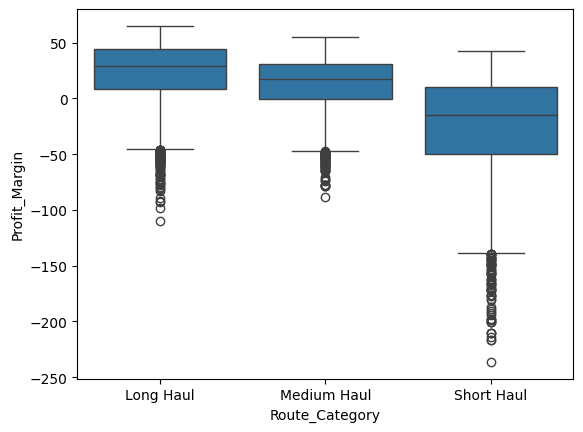

In [7]:
sns.boxplot(x="Route_Category", y="Profit_Margin", data=df)
plt.show()

**Profit Margin by Route Category**

The boxplot compares profit margins across the 3 route categories and reveals a clear difference in financial performance.


*   Long-haul routes tend to generate the highest median profit margins with relatively stable performance
*   Medium-haul routes show slightly lower profitability but remain genrally positive


*   Short-haul routes display the lowest median profit margin and exhibit the largest number of extreme negative outliers

This suggests that short-haul flights may be more vulnerable to profitabiltiy challenges potentially due to high fixed operational costs relative to revenue.


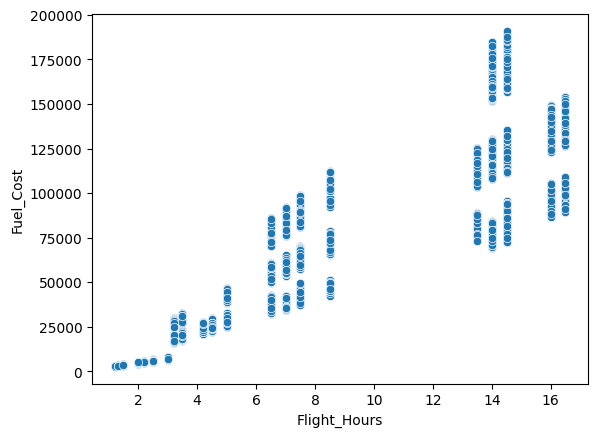

In [8]:
sns.scatterplot(x="Flight_Hours", y="Fuel_Cost", data=df)
plt.show()

**Flight Hours vs Fuel Cost**

The scatter plot between flight hours and fuel costs actually shows a strong positive relationship, indiscating that fuel cost increases substantially with flight duration. This is expected in airline operations, as longer flights consume more fuel.

The patterns reveals that flight duration is a key driver of operational costs, particularly for long-haul routes.

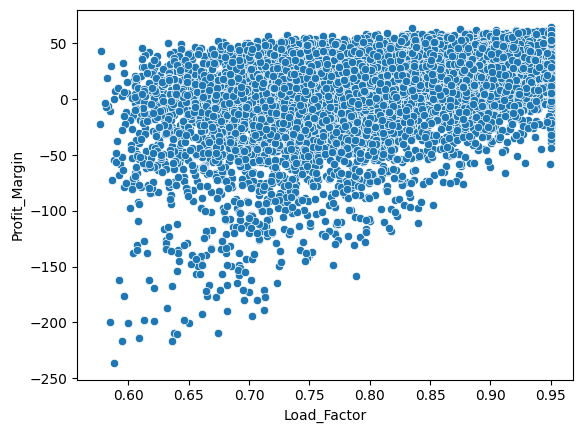

In [9]:
sns.scatterplot(x="Load_Factor", y="Profit_Margin", data=df)
plt.show()

**Load Factor vs Profit Margin**

The relationship between load factor and profit margin shows a clear upward trend, indicating that flights with higher passenger occupancy tend to generate higher profitability.

Flights with low load factors (around 60-70%) frequently experience negative profit margins, whereas flights with higher load factors (above 80%) are more likely to achieve positive profitability.

This shows that seat occupancy plays a key role in route profitability.

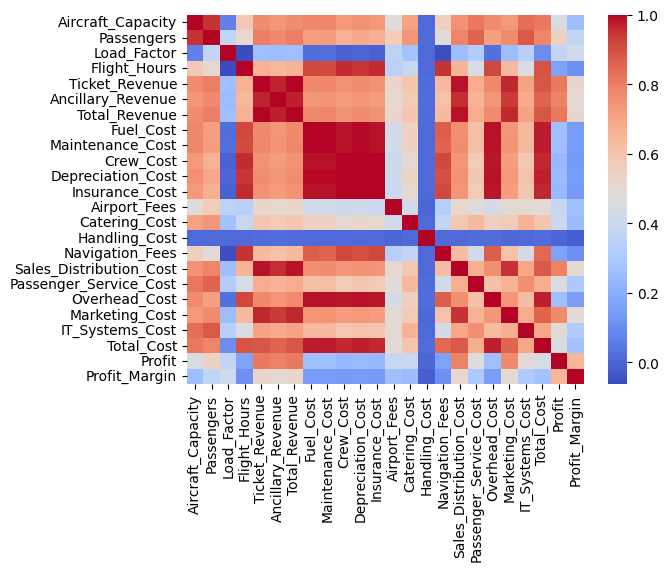

In [10]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm")
plt.show()

**Correlation Heatmap**

Strong positive correlations are shown among various cost-related variables, such as fuel cost, crew cost, and maintenance cost, suggesting that these expenses tend to increase together as flight operations scale.

Revenue variables, including ticket revenue and ancillary revenue, also show strong relationships with total revenue.

Profit margin exhibits weaker correlations with most individual variables, indicating that profitability is influenced by multiple interacting factors, including both operational costs and revenue generation.


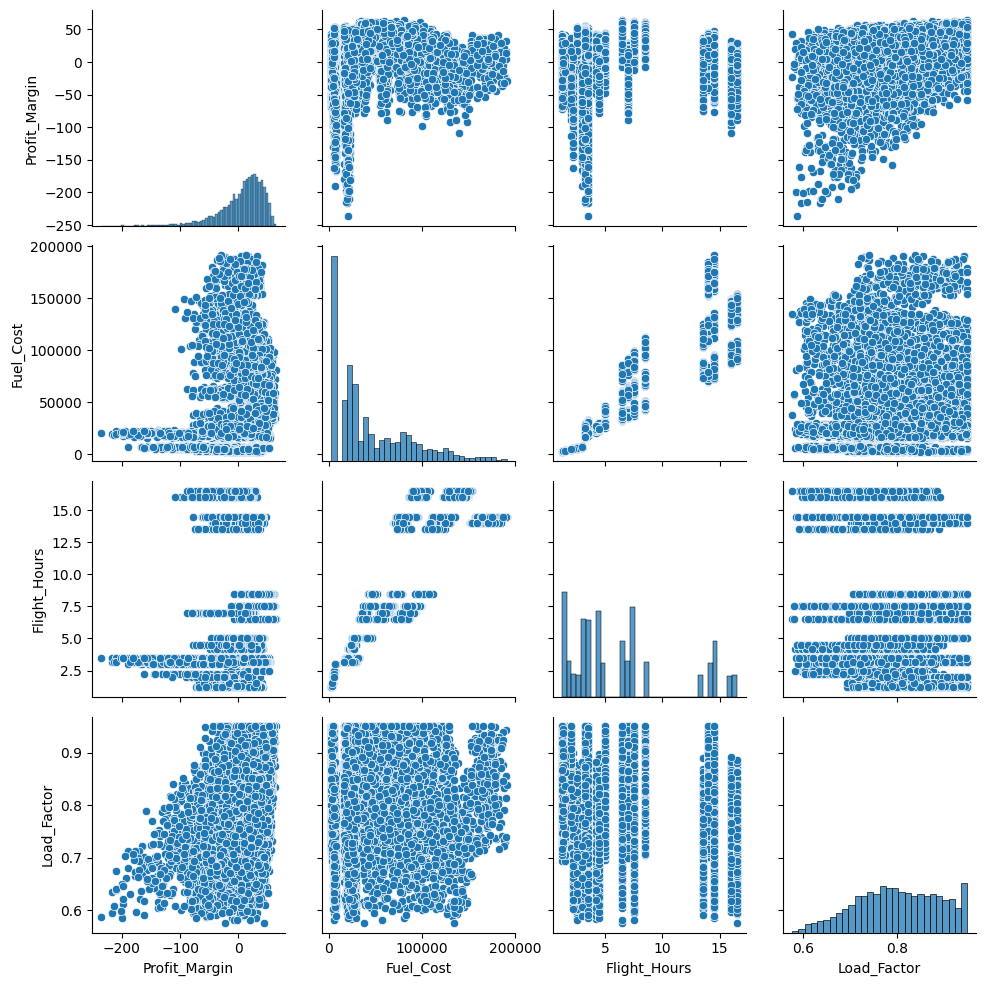

In [11]:
sns.pairplot(df[["Profit_Margin","Fuel_Cost","Flight_Hours","Load_Factor"]])
plt.show()

**Pairplot Insights**

The pairplot gives a wider view of relationships among key variables including profit margin, fuel cost, flight hours, and load factor.

Several patterns are visible:

*   Fuel cost increases with flight duration
*   Profit margin appears to improve as load factor increases

*   Profit margin does not show a strong direct relationship with fuel cost alone, suggesting profitability depends on the balance between revenue and multiple cost components


These relationships highlight the complexity of airline profitability, where both operational efficiency and passenger demand influence financial outcomes.

# **Feature Scaling**

Before applying dimensionality reduction techniques such as Principal Component Analysis (PCA), the numerical variables were standardised using StandardScaler.

Feature scaling is necessary because PCA is sensitive to differencs in variable magnitude.  Variables such as fuel cost, revenue and flight hours operate on very different numerical scales which could cause variables with larger magnitudes to dominate the analysis.

Standardisation transforms each variable so that it has:


*   a mean of 0
*   a standard deviation of 1

This ensures that all variables contribute equally to the PCA transformation and prevents variables with large numeric ranges from disproportionately influencing the principal components.



In [12]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

In [13]:
scaled_df = pd.DataFrame(scaled_data, columns=numeric_df.columns)
scaled_df.head()

,Aircraft_Capacity,Passengers,Load_Factor,Flight_Hours,Ticket_Revenue,Ancillary_Revenue,Total_Revenue,Fuel_Cost,Maintenance_Cost,Crew_Cost,...,Handling_Cost,Navigation_Fees,Sales_Distribution_Cost,Passenger_Service_Cost,Overhead_Cost,Marketing_Cost,IT_Systems_Cost,Total_Cost,Profit,Profit_Margin
0,0.791794,0.603392,-0.256066,1.794073,0.617501,0.697018,0.625079,1.965140,1.797727,1.732445,...,0.418098,2.394145,0.826528,-0.270969,1.798057,0.984370,0.726470,1.611063,-0.824709,-0.391418
1,-0.220738,-0.236215,-0.120453,-0.466989,-0.499789,-0.505976,-0.501659,-0.578791,-0.550644,-0.521305,...,1.274155,-0.264989,-0.568685,0.130810,-0.636248,-0.366307,-0.860131,-0.584147,-0.230077,0.471841
2,-0.220738,-0.043332,0.554193,0.257429,1.427563,1.548424,1.439677,-0.122556,-0.139919,0.012797,...,-0.200864,-0.123657,1.368652,0.345192,-0.149654,0.811129,0.420352,0.326616,2.358811,1.342271
3,-0.220738,-0.292945,-0.305069,-0.620653,-0.581637,-0.511093,-0.574957,-0.671668,-0.637767,-0.634600,...,0.401096,-0.596072,-0.541559,-0.405554,-0.695123,-0.526604,-0.593497,-0.638038,-0.303282,0.377061
4,-1.395275,-1.280051,-0.130709,-0.906030,-0.977415,-0.971317,-0.977877,-0.944325,-0.930253,-0.969628,...,-0.509051,-0.741894,-0.974196,-1.144775,-0.936087,-0.946368,-1.435794,-1.023897,-0.592914,-0.864033


In [14]:
scaled_df.describe()

,Aircraft_Capacity,Passengers,Load_Factor,Flight_Hours,Ticket_Revenue,Ancillary_Revenue,Total_Revenue,Fuel_Cost,Maintenance_Cost,Crew_Cost,...,Handling_Cost,Navigation_Fees,Sales_Distribution_Cost,Passenger_Service_Cost,Overhead_Cost,Marketing_Cost,IT_Systems_Cost,Total_Cost,Profit,Profit_Margin
count,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,...,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03,7.974000e+03
mean,1.151714e-16,1.096022e-16,-1.523737e-16,-1.296513e-16,-3.274698e-17,2.004917e-18,3.608851e-17,-1.737595e-17,1.113843e-17,1.176218e-16,...,8.509761e-17,1.514826e-17,-2.049471e-17,-1.372255e-16,2.976189e-16,-2.806884e-17,-3.720236e-16,-1.532648e-16,-2.895992e-17,-3.564298e-18
std,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,...,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00
min,-1.395275e+00,-1.711201e+00,-2.563765e+00,-1.125551e+00,-1.052656e+00,-1.047228e+00,-1.052358e+00,-1.013531e+00,-9.953123e-01,-1.074830e+00,...,-1.762594e+00,-1.153859e+00,-1.047903e+00,-1.730615e+00,-1.089390e+00,-1.016335e+00,-1.738992e+00,-1.130257e+00,-2.329644e+00,-6.210855e+00
25%,-2.207380e-01,-8.460650e-01,-7.378337e-01,-6.865096e-01,-8.771213e-01,-8.476262e-01,-8.767603e-01,-6.994109e-01,-6.751056e-01,-6.831544e-01,...,-8.537034e-01,-7.628692e-01,-8.618695e-01,-7.493416e-01,-7.418922e-01,-8.316017e-01,-7.512557e-01,-8.117003e-01,-5.856630e-01,-4.338763e-01
50%,7.289618e-02,-1.000626e-01,-7.943220e-04,-4.011329e-01,-3.448666e-01,-3.326945e-01,-3.471439e-01,-4.163107e-01,-4.397594e-01,-4.120569e-01,...,-1.472598e-02,-3.166925e-01,-3.325251e-01,-1.463628e-01,-3.873510e-01,-3.334322e-01,-1.372744e-01,-4.037364e-01,-3.666145e-01,2.311785e-01
75%,7.917936e-01,5.353159e-01,8.151627e-01,2.574287e-01,6.255629e-01,5.805390e-01,6.235156e-01,6.617888e-01,6.690834e-01,5.522947e-01,...,8.470617e-01,4.540394e-01,5.992834e-01,5.651216e-01,6.287023e-01,5.365502e-01,5.596509e-01,7.459196e-01,3.163771e-01,6.939311e-01
max,2.016957e+00,2.679718e+00,1.691519e+00,2.233114e+00,4.383451e+00,5.392634e+00,4.494219e+00,3.356917e+00,3.028203e+00,2.710284e+00,...,1.783093e+00,3.278046e+00,4.385621e+00,3.868867e+00,3.711442e+00,5.111129e+00,3.831819e+00,3.494489e+00,6.489312e+00,1.505445e+00


# **Principal Component Analysis (PCA)**

In [15]:
from sklearn.decomposition import PCA
pca = PCA()
pca_data = pca.fit_transform(scaled_df)

In [16]:
explained_variance = pca.explained_variance_ratio_
explained_variance

array([6.46707790e-01, 1.30576059e-01, 5.66493389e-02, 4.16899535e-02,
       3.50794104e-02, 2.43199110e-02, 1.78285237e-02, 1.64576275e-02,
       1.00704844e-02, 7.24537961e-03, 4.40329264e-03, 2.84736449e-03,
       1.97308608e-03, 1.75963111e-03, 1.19796604e-03, 7.55121288e-04,
       2.08564909e-04, 1.50575935e-04, 5.94526631e-05, 1.22149742e-05,
       7.67993863e-06, 4.02868375e-07, 1.69712301e-07, 3.01960056e-19])

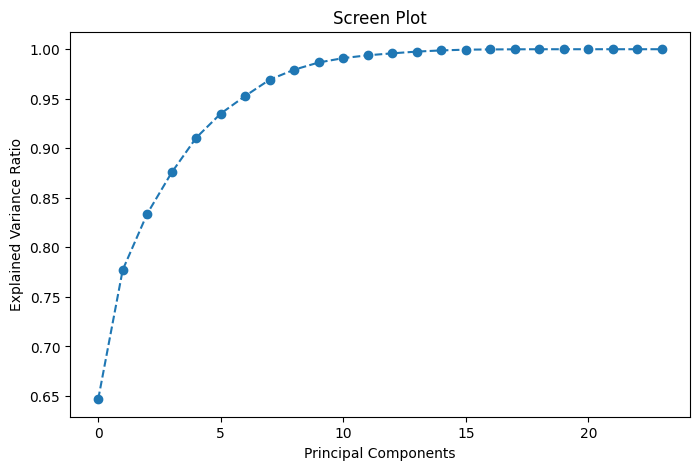

In [17]:
plt.figure(figsize=(8,5))
plt.plot(pca.explained_variance_ratio_.cumsum(), marker='o', linestyle='--')
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Screen Plot")
plt.show()

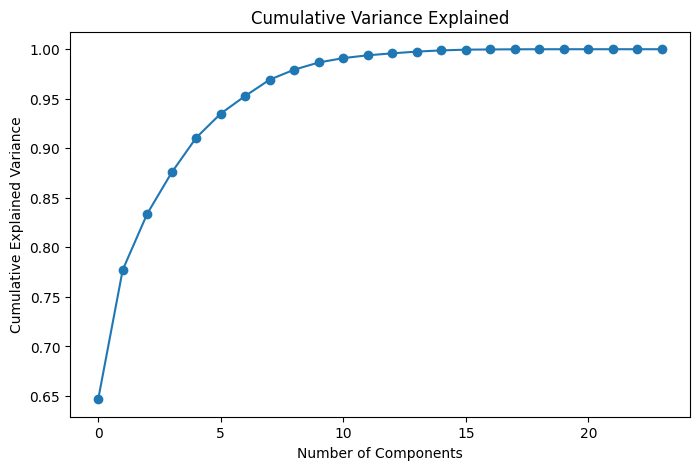

In [18]:
import numpy as np
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8,5))
plt.plot(cumulative_variance, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [19]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(scaled_df.columns))],
    index=scaled_df.columns
)
loadings.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24
Aircraft_Capacity,0.219372,0.039441,0.284760,-0.019640,-0.306593,0.038150,0.197553,-0.136293,-0.074035,-0.135821,...,0.038851,0.025178,0.035004,-0.634972,0.102470,-0.097231,-0.004061,0.001325,0.005488,-3.594119e-09
Passengers,0.218945,0.153234,0.314677,-0.014254,-0.080967,-0.055978,0.036292,-0.141169,-0.068570,-0.136797,...,0.015866,0.019462,-0.018480,0.715292,-0.118398,0.057868,0.003148,-0.001872,-0.003708,1.955191e-09
Load_Factor,0.049327,0.343940,0.159288,0.010576,0.691306,-0.377383,-0.393055,-0.061967,-0.013780,-0.094979,...,0.004547,-0.001337,0.006158,-0.211081,0.035679,-0.019172,-0.001010,0.000316,0.001290,-5.686618e-10
Flight_Hours,0.209810,-0.268405,-0.139648,0.002445,0.165171,-0.053179,0.044870,0.043906,0.045985,0.293846,...,0.142468,0.158813,0.198938,0.029439,-0.184725,-0.349664,-0.000697,0.002556,0.017924,-1.261634e-08
Ticket_Revenue,0.236788,0.147015,-0.182210,0.012761,-0.079176,0.061042,-0.114740,0.013689,0.000732,-0.008805,...,-0.167878,0.018533,0.038356,-0.007325,0.018913,-0.020133,0.883652,-0.020121,0.001104,1.601682e-08


# **PCA Results and Interpretation**

The PCA reveals that airline route performance is largely explained by 3 structural dimensions:


1.   Operational scale of flights
2.   Passanger demand efficiency

1.   Aircraft capacity characteristics

The explained variance results show that the 1st principal component (PC1) accounts for approximately 64.7% of the total variance in the dataset, indicating that a large proportaion of the vairability across airline routes is driven by a common underlying factor.

The first 2 principal components together explain approximately 78% of the total variance, while the first 4 components capture nearly 88% of the dataset variability. This suggests that the original set variables can be effectively summarised using a small number of principal components.

The screen plot shows a clear 'elbow point' after the 3rd or 4th component, idicating that additional compnenets beyond this point contribute relatively little additional inofrmation.

Analysis of the compnent loadings suggests that the 1st principal component is strongly associated with variables realted to operational scale, including aircarft capacity, passenger volume, flight duration and revenue measures. The 2nd prinicpal component appears to capture passenager demand efficiency with the load factor contributing strongly to this component.

Overall PCA reveals that airline route performance can largely be explained by underlaying factors related to flight scale, passenger demand, and operational capacity.

# **PCA Biplot**

Principal Component Analysis was further visualised using a biplot to find out how the original variables contribute to the first 2 principal components. The arrows represent the direction and magnitude of each variable's influence on the PCA space. Variables pointing in similar directions indcate positive correlation, while variables pointing in opposite directions highlight the negative relationships.

This viusalisation helps ot identify which operational and financial variables drive variation in airline route performance.

In [20]:
pca = PCA(n_components=4)
pca_scores = pca.fit_transform(scaled_df)
pca_df = pd.DataFrame(pca_scores, columns=["PC1", "PC2", "PC3", "PC4"])

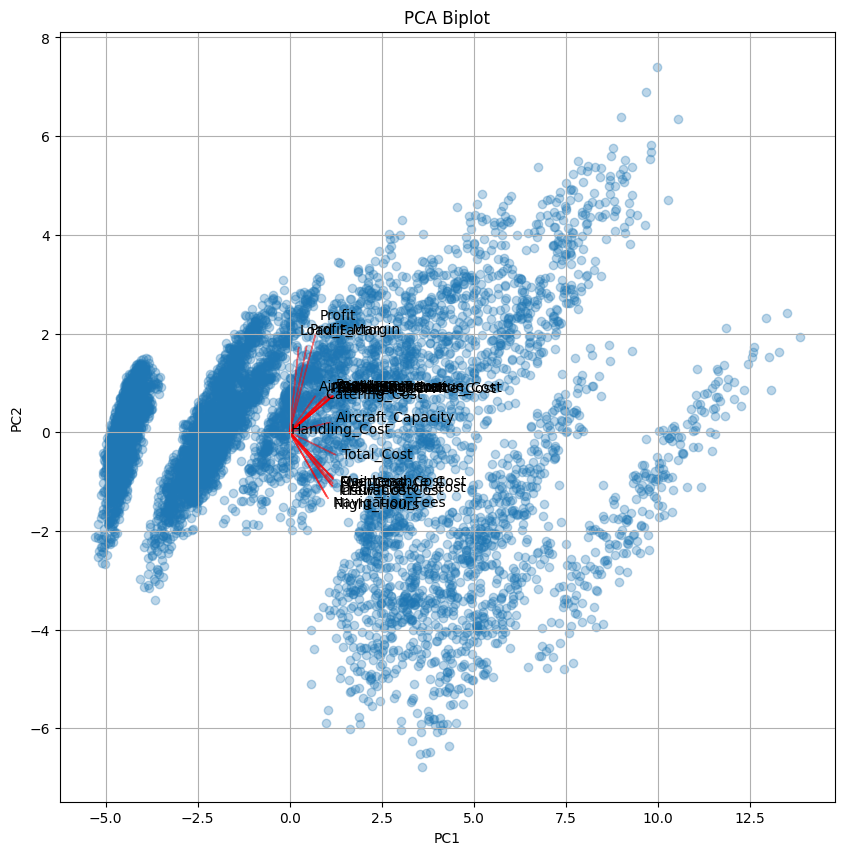

In [22]:
plt.figure(figsize=(10,10))

plt.scatter(pca_scores[:,0], pca_scores[:,1], alpha=0.3)

for i, feature in enumerate(scaled_df.columns):
  plt.arrow(
      0.0,
      0.0,
      pca.components_[0,i]*5,
      pca.components_[1,i]*5,
      color='red',
      alpha=0.5
  )

  plt.text(
      pca.components_[0,i]*5 * 1.15,
      pca.components_[1,i]*5 * 1.15,
      feature,
      color='black'
  )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.grid()
plt.show()

**PCA Biplot Interpretation**

In the plot, profitability-related variables such as profit, profit margin and load factor (capacity) appear to align in similar directions, indicating that routes with more passangers tend to generate stronger financial performance.

Conversely, several operational cost variables appear to point in opposing directions relative to profitability metrics, suggesting that higher operational costs are associated with lower profitability.

Overall, the first prinicpal component appears to capture operational scale and cost strcuture, while the second component reflects route profitability and efficiency.

# **K-Means Clustering on PCA Components**

To identify natural groupings of airline routes, K-Means clustering was used on the reduced PCA feature space. Using PCA before clustering helps reduce noise and improves clustering performance by focusing on the most informative dimensions of the dataset. The optimal number of clusters was determined using the elbow method. The resulting clusters represent groups of routes with similar operational and financial characteristics.

These clusters can provide insights into different types of airline routes, such as high-demand profitable routes, cost-intensive routes, or lower-performing routes.

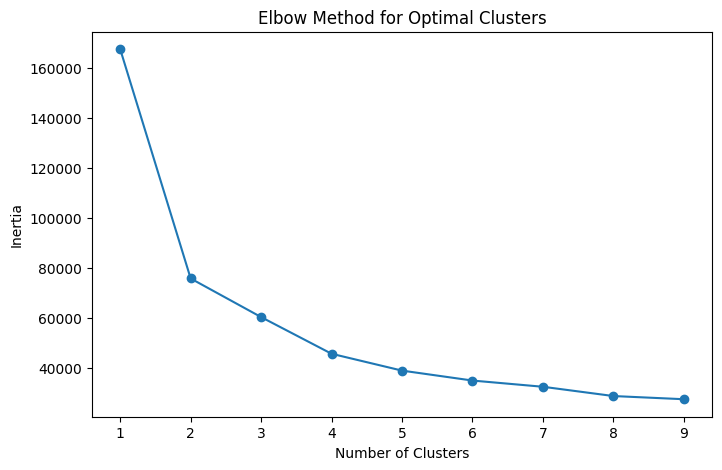

In [23]:
from sklearn.cluster import KMeans

inertia = []

K_Range = range(1,10)
for k in K_Range:
  kmeans = KMeans(n_clusters=k)
  kmeans.fit(pca_df)
  inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_Range, inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Clusters")
plt.show()

In [24]:
kmeans = KMeans(n_clusters=4, random_state=42)

clusters = kmeans.fit_predict(pca_df)

pca_df["Cluster"] = clusters

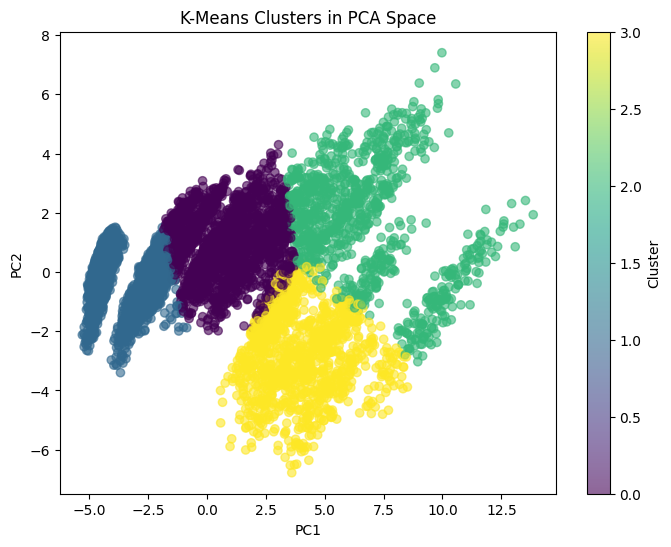

In [25]:
plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Cluster"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters in PCA Space")
plt.colorbar(label="Cluster")

plt.show()

# **Cluster Profiling Interpretation**

The cluster profiling results highlight four distinct groups of airline routes, each showing different operational and financial characteristics. By examining the average values across key performance variables, it becomes possible to interpret how different types of routes contribute to the airline’s overall network performance.

Cluster 2 clearly represents the strongest performing routes within the dataset. These routes generate the highest revenue and profit levels, while also showing the highest load factors and passenger volumes. They are also associated with longer flight durations, which suggests they may represent high-demand long-haul or major international routes. Although these routes incur high fuel costs, the strong passenger demand allows revenue to comfortably offset operational expenses, resulting in the highest profit margins across all clusters.

Cluster 0 appears to represent efficient medium-scale routes. These routes show strong profitability with a healthy profit margin and relatively balanced cost structures. Passenger demand is also strong, as reflected by a high load factor and stable passenger volumes. The moderate flight duration suggests that these routes may represent efficient medium-haul operations that generate consistent revenue while maintaining manageable operational costs.

Cluster 3 represents long-duration routes that appear to be significantly more cost-intensive to operate. These routes have the longest average flight hours and the highest fuel costs, which heavily impacts profitability. Although total revenue is relatively high, operational costs are nearly equal to revenue, resulting in slightly negative profit margins. This suggests that these routes may be strategically important long-haul routes that are expensive to operate but still necessary for maintaining network connectivity.

Cluster 1 represents the lowest performing routes within the network. These routes have the lowest revenue levels, relatively short flight durations, and negative profit margins. Passenger numbers and demand appear to be lower compared to other clusters, suggesting that these routes may represent regional or feeder routes that contribute less directly to airline profitability.

Overall, the clustering results suggest that airline route performance is largely influenced by three key factors: passenger demand, operational scale, and cost structure. Routes with strong passenger demand and higher revenue generation tend to maintain stronger profitability, while routes with high operational costs or lower demand struggle to achieve positive margins.

In [26]:
df["Cluster"] = pca_df["Cluster"]
cluster_summary = df.groupby("Cluster")[[
    "Profit_Margin",
    "Profit",
    "Total_Revenue",
    "Total_Cost",
    "Load_Factor",
    "Flight_Hours",
    "Passengers",
    "Fuel_Cost"
]].mean().round(2)

cluster_summary

,Profit_Margin,Profit,Total_Revenue,Total_Cost,Load_Factor,Flight_Hours,Passengers,Fuel_Cost
Cluster,,,,,,,,
0,27.70,116393.53,340987.51,224593.98,0.83,5.96,289.32,41933.75
1,-12.40,1151.24,78784.47,77633.23,0.78,2.79,183.88,12602.43
2,36.34,309563.80,804904.84,495341.04,0.87,9.67,409.10,102243.23
3,-3.59,6044.09,448922.36,442878.27,0.76,14.77,274.36,108461.96


**Route Category Distribution by Cluster**


To further understand the composition of each cluster, a cross-tabulation of route category and cluster membership was performed. This helps identify whether certain types of routes (long-haul, medium-haul, or short-haul) are more strongly associated with particular clusters.

The results suggest that ***Cluster 2*** and ***Cluster 3*** are dominated by long-haul routes, indicating that these clusters largely represent long-distance operations. In contrast, ***Cluster 1*** is primarily composed of short-haul routes, while ***Cluster 0*** consists of a mix of long-haul and medium-haul routes.

Examining the distribution of route categories across clusters provides additional context for interpreting the clustering results, as route distance plays an important role in determining operational costs, passenger demand, and overall profitability within airline networks.

In [27]:
route_mix = pd.crosstab(df["Cluster"], df["Route_Category"], normalize="index").round(2)
route_mix

Route_Category,Long Haul,Medium Haul,Short Haul
Cluster,,,
0,0.48,0.52,0.00
1,0.00,0.38,0.62
2,0.97,0.03,0.00
3,1.00,0.00,0.00


**Aircraft Type Distribution by Cluster**

To provide further context for the clustering results, the distribution of aircraft types within each cluster was examined. This helps identify whether certain clusters are associated with specific aircraft categories, which can provide additional insight into the operational characteristics of each route group.

The results suggest that Cluster 2 is strongly associated with large wide-body aircraft, particularly the Airbus A380 and Boeing 777-300ER, which aligns with the earlier finding that this cluster represents high-revenue long-haul routes. In contrast, Cluster 1 contains a higher proportion of narrow-body aircraft such as the Airbus A320 and Boeing 737-800, which are typically used for shorter regional or medium-haul routes.

Clusters 0 and 3 show a mix of wide-body aircraft types, including the Airbus A350-900, Boeing 777-300ER, and Boeing 787-9, suggesting these clusters may represent longer-distance routes that require larger aircraft but vary in terms of operational efficiency and profitability.

Examining aircraft distribution across clusters helps link the clustering results to real operational decisions, as aircraft type plays a key role in determining route capacity, operating costs, and overall network performance.

In [28]:
aircraft_mix = pd.crosstab(df["Cluster"], df["Aircraft_Type"], normalize="index").round(2)
aircraft_mix

Aircraft_Type,Airbus A320,Airbus A350-900,Airbus A380,Boeing 737-800,Boeing 777-300ER,Boeing 787-9
Cluster,,,,,,
0,0.00,0.26,0.04,0.00,0.38,0.32
1,0.27,0.20,0.00,0.29,0.00,0.25
2,0.00,0.00,0.65,0.00,0.33,0.03
3,0.00,0.35,0.06,0.00,0.43,0.16


**Cluster Size Distribution**

The number of observations within each cluster was examined to understand how the dataset is distributed across the identified route segments. The results show that Cluster 1 contains the largest number of flights, while Cluster 2 represents the smallest group. However, all clusters contain a substantial number of observations, indicating that the clustering structure captures meaningful patterns across the dataset rather than being driven by a small subset of flights.

Overall, the distribution suggests that the clusters are reasonably balanced, which supports the validity of the clustering results and indicates that each cluster represents a distinct but relevant segment of airline operations.

In [29]:
cluster_counts = df["Cluster"].value_counts().sort_index()
cluster_counts

,count
Cluster,
0,2243
1,3551
2,979
3,1201


# **Final Conclusions and Strategic Insights**

This analysis explored airline route performance using a combination of exploratory data analysis and unsupervised machine learning techniques. Through data cleaning, feature scaling, Principal Component Analysis (PCA), and K-Means clustering, the dataset was examined to uncover underlying operational patterns within the airline network.

The PCA results revealed that a large proportion of the variability within the dataset could be explained by a small number of underlying factors. In particular, the first few principal components captured most of the variance, suggesting that airline performance across routes is largely driven by a combination of operational scale, passenger demand efficiency, and cost structure. This indicates that variables such as passenger volume, load factor, flight duration, and operational costs play a central role in determining route performance.

Building on this dimensionality reduction, K-Means clustering was used to identify natural groupings of airline routes with similar characteristics. The clustering results revealed four distinct route segments, each with different operational and financial profiles. Some clusters were characterised by high passenger demand, strong revenue generation, and positive profit margins, indicating high-performing routes that likely represent core long-haul or high-demand services. Other clusters were associated with higher operational costs or lower demand levels, resulting in lower or negative profitability.

Further profiling of the clusters provided additional operational context. Routes associated with high-performing clusters were strongly linked with long-haul operations and larger wide-body aircraft, suggesting that these routes benefit from strong passenger demand and higher capacity utilisation. In contrast, clusters containing lower-performing routes were more closely associated with short-haul operations and narrow-body aircraft, which tend to generate lower revenue and may struggle to offset operational costs.

From a strategic perspective, these findings suggest several potential implications for airline network management. Routes with consistently high profitability and strong passenger demand represent key revenue drivers and may offer opportunities for capacity expansion or additional frequency. In contrast, routes with persistently low profit margins may require further evaluation, particularly where operational costs remain high relative to revenue generation. Airlines may consider strategies such as route restructuring, cost optimisation, or aircraft reassignment to improve efficiency within these segments.

Ultimately, this analysis demonstrates how combining exploratory data analysis with unsupervised learning techniques can reveal meaningful structure within complex operational datasets. By identifying distinct route segments and the factors that drive their performance, the approach provides a practical framework for understanding airline network dynamics.

In practice, these insights can support more informed decisions around route planning, fleet allocation, and operational efficiency, highlighting the value of data-driven methods in improving airline network performance.